### Network topology

In [ ]:
# plot network topology

from pathlib import Path
import sys
HERE = Path.cwd()

SRC = HERE.parent/'src'
sys.path.insert(0,str(SRC))

from network_topology import *

GN = GasNetwork()
GN.plot_network()

In [ ]:
# Network property

print('edges: ', EDGES)
print('length: ',LENGTH_M)
print('diameter: ',DIAMETER_M)


print('B matrix: ',B)

In [ ]:
# consumer demand

print('Demand = ', DEMAND)
print('Total withdrawal [kg/s] =', DEMAND.sum())

### Quick exercise A 

1. How many unknown pipe flows exist? How many independent nodal balance equations exist?
2. Why is mass conservation alone insufficient to determine flow in this **looped** network?
3. What extra physical relationship closes the system?

In [ ]:
# rank(B) = n − 1     
# dim ker(B) = m − n + 1 

print(f'{N} nodes, {M} pipes, B shape={B.shape}, rank={np.linalg.matrix_rank(B)}')
print('Independent cycles =',M-N+1)

### From Darcy–Weisbach to squared-pressure drop

In [ ]:


K = resistance(LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)/BAR**2
for e in range(4):
 print(f'pipe {e+1:2d}: L={LENGTH_M[e]:.0f} m, D={DIAMETER_M[e]:.2f} m, K={K[e]:.5f} bar²/(kg/s)²')


### The coupled nonlinear network solver

The source mass injection is an unknown determined by conservation. We solve the nonlinear system using SciPy least_squares and an analytical Jacobian; the residual should be near machine precision.

In [ ]:
from steady_state_solver import steady_solution

base = steady_solution(DEMAND, SUPPLY_BAR, LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)
print('Nodal pressures [bar(a)] :', np.round(base['pressure_bar'],4))
print('Oriented pipe flows [kg/s]:', np.round(base['mass_flow_kg_s'],4))
print('Total source injection:', base['source_flow_kg_s'], 'kg/s')
print('Conservation max error:',base['mass_max_kg_s'],'kg/s')
print('Hydraulic max error:',base['hydraulic_max_bar2'],'bar²')
print('Number of nonlinear function evaluations:',base['solver_evaluations'])

In [ ]:
q=base['mass_flow_kg_s'];p=base['pressure_bar']
b=np.r_[DEMAND.sum(),-DEMAND]
print('B @ q − b [kg/s]:',np.round(B@q-b,10))
print('Δ(p²) − Kq|q| [bar²]:',np.round(B.T@(p*p)-base['K_bar2']*q*np.abs(q),10))

### Quick exercise B 

- Why do we use the squared pressure as a numerical unknown?
- A pipe has \(L=2\) km and \(D=0.20\) m. If diameter increases by 20% while \(f_D\) is held constant, what is the theoretical ratio of the new to old resistance?
- Why must bar(g) values be converted to absolute pressure before squaring?

## Operational scenarios: demand, pressure and pipe sizing

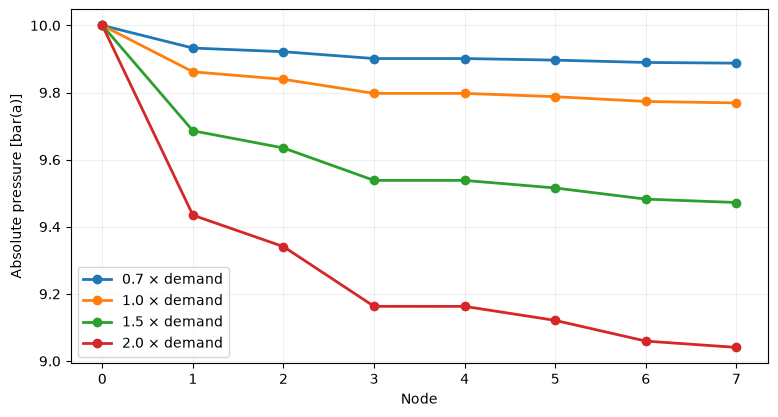

In [9]:
fig,ax=plt.subplots(figsize=(9,4.6))
for scale in [0.7,1.,1.5,2.]:
    result=steady_solution(DEMAND*scale,SUPPLY_BAR, LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)
    ax.plot(range(N), result['pressure_bar'], 'o-',lw=2,label=f'{scale:.1f} × demand')
ax.set_xticks(range(N)); ax.set(xlabel='Node',ylabel='Absolute pressure [bar(a)]')
ax.grid(alpha=.18);ax.legend();plt.show()

Minimum pressure, original network [bar(a)]: 9.3167
Minimum pressure, reinforced network [bar(a)]: 9.7
Pipe 1 resistance ratio (new/old): 0.156


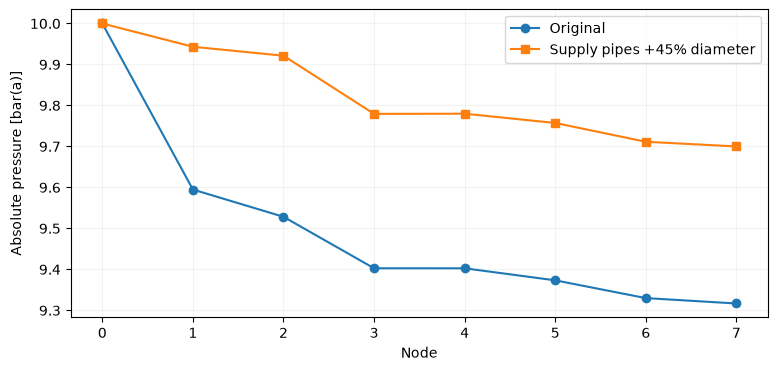

In [13]:
factor=1.7
before=steady_solution(DEMAND*factor,SUPPLY_BAR, LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)
new_D=DIAMETER_M.copy();new_D[:2]*=1.45  # reinforce two main supply branches
after=steady_solution(DEMAND*factor,SUPPLY_BAR, LENGTH_M, new_D, FRICTION, TEMP, RS, Z)
print('Minimum pressure, original network [bar(a)]:',round(before['pressure_bar'].min(),4))
print('Minimum pressure, reinforced network [bar(a)]:',round(after['pressure_bar'].min(),4))
print('Pipe 1 resistance ratio (new/old):', round((DIAMETER_M[0]/new_D[0])**5,4))
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(range(N),before['pressure_bar'],'o-',label='Original')
ax.plot(range(N),after['pressure_bar'],'s-',label='Supply pipes +45% diameter')
ax.set(xlabel='Node',ylabel='Absolute pressure [bar(a)]');ax.set_xticks(range(N));ax.legend();ax.grid(alpha=.15);plt.show()

### Challenge 

**A pressure constraint:** Assume the lowest allowed absolute pressure is **9.0 bar(a)**. Increase total demand uniformly and determine the largest feasible multiplier of the baseline demand **for this simplified model**. Use bisection or `scipy.optimize.brentq` on the minimum pressure difference.

**Hint:** Define `g(alpha) = steady_solution(DEMAND * alpha)['pressure_bar'].min() - 9.0`. Then bracket a root between 1 and 3. This is not an optimal hydraulic control problem; it is a scalar feasibility experiment.

In [15]:
from scipy.optimize import brentq
min_pressure=9.0
alpha=brentq(lambda a: steady_solution(DEMAND*a,SUPPLY_BAR, LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)['pressure_bar'].min()-min_pressure,1.,3.)
print(f'Worked solution: max uniform multiplier = {alpha:.3f}')
print('Pressure at limiting node [bar(a)]:',steady_solution(DEMAND*alpha,SUPPLY_BAR, LENGTH_M, DIAMETER_M, FRICTION, TEMP, RS, Z)['pressure_bar'].min())

Worked solution: max uniform multiplier = 2.040
Pressure at limiting node [bar(a)]: 9.00000000000011
